# Full-throttle speed loss: 2025 vs 2026 qualifying, paired by straight

The same pipeline (`flatout.run_session`, same cleaning and QC) runs on 2025 qualifying at every circuit that has also hosted 2026 qualifying so far. Circuits are matched by OpenF1 `circuit_key`, not by event name; Madrid (new in 2026) and the 2026 Sepang round have no 2025 counterpart. A straight is compared when it appears in both years (same circuit, corner label and main-straight flag) with >= 10 clean drivers in each year.

**Caveats.** 2025 cars differ in many ways (MGU-H, 120 kW MGU-K, DRS in qualifying, aerodynamics), so year differences reflect the whole 2026 package, not one rule. Pooling 2026 across PUs is justified by the season result (no detectable PU difference), which is not proof that none exists. C5.2.8 values are not computed for 2025 (a 2026 rule). Descriptive only.

In [1]:
import json
import re
from pathlib import Path

import fastf1
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.collections import LineCollection

from flatout import (FIG, OPENF1_CACHE, PU_2025, XY_UNIT_M, caption, freeze_mask, full_throttle_segments, line_window, lap_pos,
                     load_openf1_brake, load_quali, openf1_session_key, push_laps, run_session, to_seconds, xy_cumdist)

MIN_CLEAN_DRIVERS = 10
OUT25, OUT26 = Path("data/season2025"), Path("data/season")
OUT25.mkdir(parents=True, exist_ok=True)


def circuit_of(year, rnd):
    """(OpenF1 session_key, circuit_key, circuit_short_name) of an event's main Qualifying."""
    key = openf1_session_key(year, rnd)
    ses = pd.DataFrame(json.loads((OPENF1_CACHE / f"sessions_{year}_qualifying.json").read_text()))
    row = ses[ses.session_key == key]
    return (key, int(row.circuit_key.iloc[0]), row.circuit_short_name.iloc[0]) if len(row) else (key, None, None)


qc26 = pd.read_csv(OUT26 / "qc_summary.csv")
qc26 = qc26[qc26.Status.eq("ok") & ~qc26.Event.eq("Bahrain Grand Prix")]  # 2026 Bahrain GP was held at Sepang: no 2025 counterpart
e26 = pd.DataFrame([dict(Round26=r.Round, Event26=r.Event, **dict(zip(["Key26", "Circuit", "CircuitName"], circuit_of(2026, r.Round))))
                    for r in qc26.itertuples()])
sch25 = fastf1.get_event_schedule(2025, include_testing=False)
sch25 = sch25[sch25.EventFormat.isin(["conventional", "sprint_qualifying"])]
e25 = pd.DataFrame([dict(Round25=r.RoundNumber, Event25=r.EventName, Location25=r.Location,
                         **dict(zip(["Key25", "Circuit", "_"], circuit_of(2025, r.RoundNumber)))) for r in sch25.itertuples()]).drop(columns="_")
pairs = e26.merge(e25, on="Circuit").sort_values("Round26").reset_index(drop=True)
print("2025 team -> PU:", PU_2025, "\n")
print(pairs[["CircuitName", "Round25", "Event25", "Round26", "Event26", "Key25", "Key26"]].to_string(index=False))
print("\n2026 sessions without a 2025 counterpart:", sorted(set(e26.Event26) - set(pairs.Event26)) or "none")

req         WARNING 	DEFAULT CACHE ENABLED! (56.0 KB) C:\Users\User\AppData\Local\Temp\fastf1


2025 team -> PU: {'Mercedes': 'Mercedes', 'McLaren': 'Mercedes', 'Williams': 'Mercedes', 'Aston Martin': 'Mercedes', 'Ferrari': 'Ferrari', 'Haas F1 Team': 'Ferrari', 'Kick Sauber': 'Ferrari', 'Red Bull Racing': 'Honda RBPT', 'Racing Bulls': 'Honda RBPT', 'Alpine': 'Renault'} 

      CircuitName  Round25               Event25  Round26               Event26  Key25  Key26
        Melbourne        1 Australian Grand Prix        1 Australian Grand Prix   9689  11230
         Shanghai        2    Chinese Grand Prix        2    Chinese Grand Prix   9994  11241
           Suzuka        3   Japanese Grand Prix        3   Japanese Grand Prix  10002  11249
            Miami        6      Miami Grand Prix        4      Miami Grand Prix  10029  11276
         Montreal       10   Canadian Grand Prix        5   Canadian Grand Prix   9959  11287
      Monte Carlo        8     Monaco Grand Prix        6     Monaco Grand Prix   9975  11295
        Catalunya        9    Spanish Grand Prix        7  Barce

## 2025 sessions (same cleaning and QC)

In [2]:
rows = []
for p in pairs.itertuples():
    row = dict(Round25=p.Round25, Event25=p.Event25, Circuit=p.CircuitName)
    try:
        tables, qc = run_session(2025, p.Round25, openf1_session=p.Key25)
        stem = OUT25 / f"{p.Round25:02d}_{re.sub(r'[^A-Za-z0-9]+', '_', p.Location25).strip('_').lower()}"
        to_seconds(tables["sectors"]).to_csv(f"{stem}_sectors.csv", index=False)
        to_seconds(tables["segments"]).to_csv(f"{stem}_segments.csv", index=False)
        tables["exclusions"].to_csv(f"{stem}_exclusions.csv", index=False)
        row.update(Status="ok", **{k: qc[k] for k in ["brake_source", "circuit_info", "push_laps", "push_lap_frozen_pct_mean"]})
    except Exception as e:
        row.update(Status=f"error: {type(e).__name__}: {e}")
    rows.append(row)
    print(f"2025 round {p.Round25:2d} {p.Event25:<28} {row['Status'][:70]}", flush=True)
qc25 = pd.DataFrame(rows)
qc25.to_csv(OUT25 / "qc_summary.csv", index=False)
qc25.rename(columns={"push_lap_frozen_pct_mean": "FreezeShare_pct"}).round(2)

core        WARNING 	Fixed incorrect tyre stint information for driver '4'


2025 round  1 Australian Grand Prix        ok


2025 round  2 Chinese Grand Prix           ok


2025 round  3 Japanese Grand Prix          ok


2025 round  6 Miami Grand Prix             ok


...

2025 round 15 Dutch Grand Prix             ok


2025 round 16 Italian Grand Prix           ok


2025 round 17 Azerbaijan Grand Prix        ok


2025 round 18 Singapore Grand Prix         ok


,Round25,Event25,Circuit,Status,brake_source,circuit_info,push_laps,FreezeShare_pct
0,1,Australian Grand Prix,Melbourne,ok,OpenF1,ok,87,0.01
1,2,Chinese Grand Prix,Shanghai,ok,OpenF1,ok,96,0.00
2,3,Japanese Grand Prix,Suzuka,ok,OpenF1,ok,94,0.02
3,6,Miami Grand Prix,Miami,ok,OpenF1,ok,93,0.00
4,10,Canadian Grand Prix,Montreal,ok,OpenF1,ok,112,0.03
5,8,Monaco Grand Prix,Monte Carlo,ok,OpenF1,ok,134,0.00
6,9,Spanish Grand Prix,Catalunya,ok,OpenF1,ok,78,0.00
7,11,Austrian Grand Prix,Spielberg,ok,OpenF1,ok,97,0.00
8,12,British Grand Prix,Silverstone,ok,OpenF1,ok,91,0.06
9,13,Belgian Grand Prix,Spa-Francorchamps,ok,OpenF1,ok,83,0.05


In [3]:
_ok = qc25[qc25.Status.eq("ok")]
caption("Table", "qc25", f"2025 qualifying sessions at circuits also raced in 2026: {len(_ok)} of {len(qc25)} ran; freeze share per session "
        f"{_ok.push_lap_frozen_pct_mean.min():.2f}–{_ok.push_lap_frozen_pct_mean.max():.2f} % (mean {_ok.push_lap_frozen_pct_mean.mean():.2f} %); "
        f"brake source: {', '.join(sorted(_ok.brake_source.unique()))}.")

*Table 1. 2025 qualifying sessions at circuits also raced in 2026: 15 of 15 ran; freeze share per session 0.00–0.06 % (mean 0.01 %); brake source: OpenF1.*

## Paired comparison by straight

Per straight and year, across drivers' selected segments: median vmax_position, median clip_delta, the share of drivers whose peak comes before the segment end (vmax_position < 1) and, as a sensitivity check on that share, the share with clip_delta >= 2 km/h. Difference = 2026 − 2025.

In [4]:
def load_year(year, out, rnd_col):
    """Selected segments of one year at the paired circuits, with a straight key (circuit, label, main flag)."""
    frames = []
    for p in pairs.itertuples():
        f = next(out.glob(f"{getattr(p, rnd_col):02d}_*_segments.csv"), None)
        if f is not None:
            frames.append(pd.read_csv(f).assign(Circuit=p.CircuitName, Round=getattr(p, rnd_col)))
    d = pd.concat(frames, ignore_index=True)
    d["Straight"] = d.Circuit + " " + np.where(d.CrossesTimingLine, "main", d.Label)
    d = d[d.groupby("Straight").Driver.transform("nunique") >= MIN_CLEAN_DRIVERS]
    return d.assign(Year=year)


seg = pd.concat([load_year(2025, OUT25, "Round25"), load_year(2026, OUT26, "Round26")], ignore_index=True)
per = seg.groupby(["Straight", "Year"]).agg(vmax_position=("vmax_position", "median"), clip_delta=("clip_delta", "median"),
                                            PeakBeforeEnd=("vmax_position", lambda x: (x < 1).mean()),
                                            Clip2Share=("clip_delta", lambda x: (x >= 2).mean()),
                                            Drivers=("Driver", "nunique")).unstack("Year").dropna()
METRICS = {"vmax_position": "median vmax_position", "clip_delta": "median clip_delta (km/h)",
           "PeakBeforeEnd": "share with peak before segment end", "Clip2Share": "share with clip_delta >= 2 km/h"}


def paired_summary(per):
    """Per metric: n straights, median per year, median and IQR of the 2026 - 2025 difference, shares of straights higher/lower in 2026."""
    d = pd.DataFrame({m: per[(m, 2026)] - per[(m, 2025)] for m in METRICS})
    return pd.DataFrame({m: {"n straights": len(d), "median 2025": per[(m, 2025)].median(), "median 2026": per[(m, 2026)].median(),
                             "median difference": d[m].median(), "q25": d[m].quantile(.25), "q75": d[m].quantile(.75),
                             "share 2026 > 2025": (d[m] > 0).mean(), "share 2026 < 2025": (d[m] < 0).mean()} for m in METRICS}).T, d


summary, diff = paired_summary(per)
print(per.round(2).to_string(), "\n")
summary.round(2)

                      vmax_position       clip_delta       PeakBeforeEnd       Clip2Share       Drivers      
Year                           2025  2026       2025  2026          2025  2026       2025  2026    2025  2026
Straight                                                                                                     
Baku T15                       1.00  0.71        0.0  21.5          0.05  1.00       0.00  1.00    20.0  22.0
Baku T3                        1.00  0.94        0.0   2.0          0.30  0.81       0.15  0.57    20.0  21.0
Baku main                      1.00  0.99        0.0   1.0          0.05  0.59       0.00  0.27    20.0  22.0
Catalunya main                 0.94  0.76        2.0  21.0          0.95  1.00       0.60  1.00    20.0  22.0
Hungaroring main               1.00  0.92        0.0   7.0          0.20  0.68       0.05  0.64    20.0  22.0
Melbourne T11                  1.00  0.85        0.0  10.5          0.00  0.94       0.00  0.94    19.0  18.0
Melbourne 

,n straights,median 2025,median 2026,median difference,q25,q75,share 2026 > 2025,share 2026 < 2025
vmax_position,39.0,0.99,0.77,-0.15,-0.29,-0.04,0.00,0.85
clip_delta,39.0,0.50,9.50,7.50,3.50,20.75,0.85,0.00
PeakBeforeEnd,39.0,0.50,1.00,0.31,0.10,0.51,0.87,0.03
Clip2Share,39.0,0.25,1.00,0.40,0.16,0.68,0.87,0.00


In [5]:
def headline(per, diff):
    """Headline sentence, computed: earlier peak and more speed lost / reverse / no clipping in either year."""
    both = (diff.vmax_position < 0) & (diff.clip_delta > 0)
    reverse = (diff.vmax_position > 0) | (diff.clip_delta < 0)
    rest = ~both & ~reverse
    no_clip = ((per[("clip_delta", 2025)] == 0) & (per[("clip_delta", 2026)] == 0))[rest]
    return (f"On {both.mean():.0%} of matched straights 2026 cars peak earlier and lose more speed at full throttle; on "
            f"{'none' if reverse.sum() == 0 else f'{reverse.sum()} ({reverse.mean():.0%})'} is it the reverse; the rest "
            + ("show no clipping in either year." if no_clip.all() else f"are mixed ({(~no_clip).sum()} with clipping in at least one year)."))


caption("Table", "paired", headline(per, diff) + f" {len(diff)} straights present in both years with >= {MIN_CLEAN_DRIVERS} clean drivers each, at "
        f"{per.index.str.rsplit(' ', n=1).str[0].nunique()} circuits. Difference 2026 − 2025 per straight (median, IQR, share of straights with "
        "2026 > 2025): " + "; ".join(
            f"{METRICS[m]}: {diff[m].median():+.2f} (IQR {diff[m].quantile(.25):+.2f} to {diff[m].quantile(.75):+.2f}), 2026 > 2025 on "
            f"{(diff[m] > 0).mean():.0%}" for m in METRICS)
        + ". Speed is reported in integer km/h, so a drag-limited plateau can register a peak before the segment end with negligible speed loss; "
        "the share with clip_delta >= 2 km/h is the sensitivity check on that measure. Year differences reflect the whole 2026 package (no MGU-H, "
        "350 kW MGU-K, no DRS, new aero), not one rule; 2026 is pooled across PUs, justified by the season result (no detectable PU difference), "
        "which is not proof of none. Descriptive.")

*Table 2. On 85% of matched straights 2026 cars peak earlier and lose more speed at full throttle; on none is it the reverse; the rest show no clipping in either year. 39 straights present in both years with >= 10 clean drivers each, at 15 circuits. Difference 2026 − 2025 per straight (median, IQR, share of straights with 2026 > 2025): median vmax_position: -0.15 (IQR -0.29 to -0.04), 2026 > 2025 on 0%; median clip_delta (km/h): +7.50 (IQR +3.50 to +20.75), 2026 > 2025 on 85%; share with peak before segment end: +0.31 (IQR +0.10 to +0.51), 2026 > 2025 on 87%; share with clip_delta >= 2 km/h: +0.40 (IQR +0.16 to +0.68), 2026 > 2025 on 87%. Speed is reported in integer km/h, so a drag-limited plateau can register a peak before the segment end with negligible speed loss; the share with clip_delta >= 2 km/h is the sensitivity check on that measure. Year differences reflect the whole 2026 package (no MGU-H, 350 kW MGU-K, no DRS, new aero), not one rule; 2026 is pooled across PUs, justified by the season result (no detectable PU difference), which is not proof of none. Descriptive.*

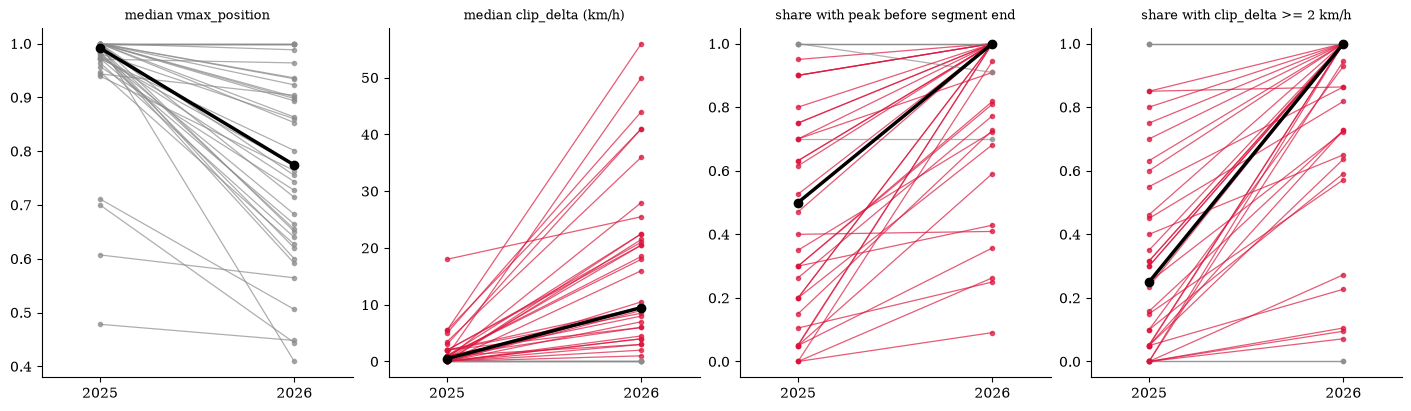

In [6]:
fig, axes = plt.subplots(1, len(METRICS), figsize=(14, 4), layout="constrained")
for ax, (m, label) in zip(axes, METRICS.items()):
    for s, r in per.iterrows():
        up = r[(m, 2026)] > r[(m, 2025)]
        ax.plot([0, 1], [r[(m, 2025)], r[(m, 2026)]], color="crimson" if up else "0.55", lw=0.9, alpha=0.7, marker="o", ms=3)
    ax.plot([0, 1], [per[(m, 2025)].median(), per[(m, 2026)].median()], color="black", lw=2.5, marker="o", ms=6)
    ax.set_xticks([0, 1], ["2025", "2026"])
    ax.set_xlim(-0.3, 1.3)
    ax.set_title(label, fontsize=9)
fig.savefig(FIG / "fig_regs_paired_straights.pdf")
plt.show()

In [7]:
caption("Figure", "paired", f"Paired straights, 2025 vs 2026 ({len(per)} straights): each line is one straight (red = higher in 2026, grey = lower or equal), "
        "black = median across straights. Panels: median vmax_position, median clip_delta, share of drivers whose peak comes before the segment end "
        "(can be inflated by integer-km/h plateaus), share with clip_delta >= 2 km/h. "
        "Year differences reflect the whole 2026 package, not one rule. Descriptive.")

*Figure 1. Paired straights, 2025 vs 2026 (39 straights): each line is one straight (red = higher in 2026, grey = lower or equal), black = median across straights. Panels: median vmax_position, median clip_delta, share of drivers whose peak comes before the segment end (can be inflated by integer-km/h plateaus), share with clip_delta >= 2 km/h. Year differences reflect the whole 2026 package, not one rule. Descriptive.*

## Suzuka: the straight through 130R, 2025 vs 2026

One clean lap per year: the fastest lap among each year's selected T14→T16 segments (freeze-free by selection). Speed is plotted against distance normalised along that segment (0 = segment start, 1 = segment end).

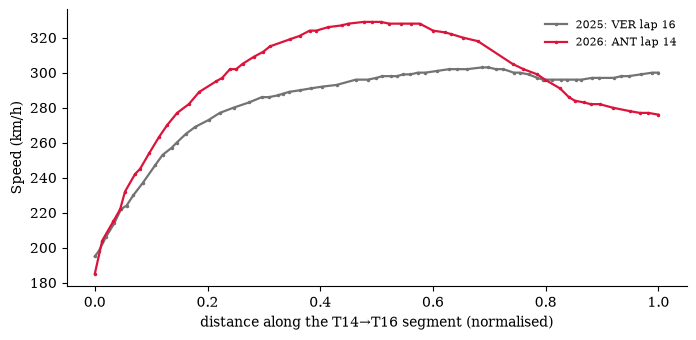

In [8]:
traces = {}
fig, ax = plt.subplots(figsize=(8, 3.6))
for year, out, rnd_col, color in [(2025, OUT25, "Round25", "0.45"), (2026, OUT26, "Round26", "crimson")]:
    rnd = int(pairs.loc[pairs.CircuitName == "Suzuka", rnd_col].iloc[0])
    s16 = pd.read_csv(next(out.glob(f"{rnd:02d}_*_segments.csv")))
    r = s16[(s16.Label == "T16") & ~s16.CrossesTimingLine].sort_values("LapTime_s").iloc[0]
    lap = load_quali(year, rnd).laps.pick_drivers(r.Driver).pick_laps(int(r.LapNumber)).iloc[0]
    car = lap.get_car_data().add_distance()
    car = car[car.Distance.between(r.start_m, r.end_m)]
    x = (car.Distance - r.start_m) / (r.end_m - r.start_m)
    ax.plot(x, car.Speed, color=color, lw=1.6, marker=".", ms=3, label=f"{year}: {r.Driver} lap {int(r.LapNumber)}")
    traces[year] = r
ax.set(xlabel="distance along the T14→T16 segment (normalised)", ylabel="Speed (km/h)")
ax.legend(frameon=False, fontsize=8)
fig.savefig(FIG / "fig_regs_suzuka_t16_traces.pdf")
plt.show()

In [9]:
caption("Figure", "suzuka", "Speed along the Suzuka T14→T16 straight (through 130R), fastest selected lap per year: " + "; ".join(
    f"{y} {r.Driver} lap {int(r.LapNumber)}: peak {r.peak_speed:.0f} km/h at vmax_position {r.vmax_position:.2f}, clip_delta {r.clip_delta:.0f} km/h"
    for y, r in traces.items()) + ". One lap per year; 2025 and 2026 cars differ in many ways (MGU-H, 120 kW MGU-K, DRS, aero). Descriptive.")

*Figure 2. Speed along the Suzuka T14→T16 straight (through 130R), fastest selected lap per year: 2025 VER lap 16: peak 303 km/h at vmax_position 0.70, clip_delta 3 km/h; 2026 ANT lap 14: peak 329 km/h at vmax_position 0.51, clip_delta 53 km/h. One lap per year; 2025 and 2026 cars differ in many ways (MGU-H, 120 kW MGU-K, DRS, aero). Descriptive.*

## Robustness checks

1. **Straight end position (telemetry).** For every selected segment on a matched straight, the X/Y of its end point is taken from position data (nearest position sample to the segment's end along the lap). Per straight and year, the median end X/Y is compared between 2025 and 2026; a straight is flagged if it moved more than 50 m (layout change, renumbering or a different map frame). FastF1's corner maps are identical across years, so they cannot serve this purpose.
2. **Rain.** A session is flagged as wet if FastF1 weather data report rainfall at any point in qualifying; a circuit is flagged if either year was wet.

The paired result is recomputed excluding each set of flags. The same pass also collects each driver-straight's speed profile for the report figures.

In [10]:
SHIFT_FLAG_M = 50  # a straight whose median end point moved more than this between years is flagged
GRID = np.linspace(0, 1, 101)  # normalised distance along a segment
matched = seg[seg.Straight.isin(per.index)].reset_index(drop=True)
sessions, ends, profiles, wet = {}, [], {2025: [], 2026: []}, []
for (year, rnd), rows in matched.groupby(["Year", "Round"]):
    ses = sessions.setdefault((year, rnd), load_quali(year, rnd))
    w = ses.weather_data
    wet.append(dict(Circuit=rows.Circuit.iloc[0], Year=year, RainfallSamples=int(w["Rainfall"].sum())))
    for r in rows.itertuples():
        lap = ses.laps.pick_drivers(r.Driver).pick_laps(int(r.LapNumber)).iloc[0]
        pos = lap_pos(lap)
        xyd = xy_cumdist(pos)
        i = int(np.abs(xyd - (r.end_m if r.CrossesTimingLine else r.EndPos_m)).argmin())  # main straight: end_m is from the line
        ends.append(dict(Straight=r.Straight, Year=year, X=pos["X"].iloc[i], Y=pos["Y"].iloc[i]))
        car = line_window(ses, lap)[0] if r.CrossesTimingLine else lap.get_car_data().add_distance()
        c = car[car.Distance.between(r.start_m, r.end_m)]
        profiles[year].append(np.interp(GRID, (c.Distance - r.start_m) / (r.end_m - r.start_m), c.Speed / r.peak_speed))
ends = pd.DataFrame(ends).groupby(["Straight", "Year"])[["X", "Y"]].median().unstack("Year")
moved_m = np.hypot(ends[("X", 2026)] - ends[("X", 2025)], ends[("Y", 2026)] - ends[("Y", 2025)]) * XY_UNIT_M
moved = moved_m.index[moved_m > SHIFT_FLAG_M]
wet = pd.DataFrame(wet).assign(Wet=lambda x: x.RainfallSamples > 0)
wet_circuits = sorted(set(wet.loc[wet.Wet, "Circuit"]))
print("Median segment end point moved between years (m):")
print(moved_m.round(1).sort_values(ascending=False).to_string(), "\n")
print(wet.pivot(index="Circuit", columns="Year", values="Wet").to_string())

core        WARNING 	Fixed incorrect tyre stint information for driver '4'


core        WARNING 	Fixed incorrect tyre stint information for driver '16'


core        WARNING 	Fixed incorrect tyre stint information for driver '1'


core        WARNING 	Fixed incorrect tyre stint information for driver '5'


core        WARNING 	Fixed incorrect tyre stint information for driver '12'


...

core        WARNING 	No lap data for driver 18


core        WARNING 	No lap data for driver 55


core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 18)


core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 55)


Median segment end point moved between years (m):
Straight
Hungaroring main         32.4
Shanghai main            30.3
Suzuka main              27.5
Catalunya main           25.5
Silverstone T9           24.5
Baku T15                 21.2
Singapore T16            20.5
Miami T11                18.2
Zandvoort T7             18.1
Spielberg T9             18.0
Spielberg main           17.5
Shanghai T14             15.7
Spielberg T4             15.7
Melbourne T9             14.3
Montreal T13             13.8
Suzuka T13               13.6
Zandvoort main           12.4
Spa-Francorchamps T12    12.0
Miami T17                11.8
Spielberg T3             11.7
Baku T3                  10.1
Miami main                9.8
Silverstone T12           9.7
Silverstone T6            9.5
Montreal main             9.1
Singapore T7              8.5
Montreal T8               6.5
Monte Carlo T10           6.3
Monza T8                  5.5
Melbourne T11             4.7
Suzuka T16                4.3
Monza T11  

In [11]:
caption("Table", "checks", f"Robustness flags for the {len(per)} matched straights. Median segment end point, 2025 vs 2026 (position data): moved "
        f"{moved_m.min():.0f}–{moved_m.max():.0f} m (median {moved_m.median():.0f} m); flagged (> {SHIFT_FLAG_M} m): "
        + (", ".join(f"{s} ({moved_m[s]:.0f} m)" for s in moved) or "none")
        + ". Rain during qualifying: " + (", ".join(f"{r.Circuit} {r.Year}" for r in wet[wet.Wet].itertuples()) or "none") + ".")

*Table 3. Robustness flags for the 39 matched straights. Median segment end point, 2025 vs 2026 (position data): moved 0–32 m (median 12 m); flagged (> 50 m): none. Rain during qualifying: Baku 2025, Montreal 2026, Zandvoort 2026.*

In [12]:
circuit_of_straight = per.index.str.rsplit(" ", n=1).str[0]
subsets = {"all matched straights": per,
           f"excl. end moved > {SHIFT_FLAG_M} m": per[~per.index.isin(moved)],
           "excl. wet sessions": per[~circuit_of_straight.isin(wet_circuits)],
           "excl. both": per[~per.index.isin(moved) & ~circuit_of_straight.isin(wet_circuits)]}
rob = pd.concat({k: paired_summary(v)[0][["n straights", "median difference", "q25", "q75", "share 2026 > 2025", "share 2026 < 2025"]]
                 for k, v in subsets.items()})
rob.round(2)

n straights  median difference   q25    q75  share 2026 > 2025  share 2026 < 2025
all matched straights  vmax_position         39.0              -0.15 -0.29  -0.04               0.00               0.85
                       clip_delta            39.0               7.50  3.50  20.75               0.85               0.00
                       PeakBeforeEnd         39.0               0.31  0.10   0.51               0.87               0.03
                       Clip2Share            39.0               0.40  0.16   0.68               0.87               0.00
excl. end moved > 50 m vmax_position         39.0              -0.15 -0.29  -0.04               0.00               0.85
                       clip_delta            39.0               7.50  3.50  20.75               0.85               0.00
                       PeakBeforeEnd         39.0               0.31  0.10   0.51               0.87               0.03
                       Clip2Share            39.0               0.40  0.16   0.68               0.87               0.00
excl. wet sessions     vmax_position         31.0              -0.17 -0.30  -0.04               0.00               0.84
                       clip_delta            31.0               7.50  4.00  22.00               0.84               0.00
                       PeakBeforeEnd         31.0               0.25  0.10   0.43               0.84               0.03
                       Clip2Share            31.0               0.37  0.13   0.66               0.84               0.00
excl. both             vmax_position         31.0              -0.17 -0.30  -0.04               0.00               0.84
                       clip_delta            31.0               7.50  4.00  22.00               0.84               0.00
                       PeakBeforeEnd         31.0               0.25  0.10   0.43               0.84               0.03
                       Clip2Share            31.0               0.37  0.13   0.66               0.84               0.00

In [13]:
caption("Table", "robust", "Paired 2026 − 2025 result under each robustness check. " + " ".join(
    f"{k} ({len(v)} straights): " + headline(v, paired_summary(v)[1]) for k, v in subsets.items()) + " Descriptive.")

*Table 4. Paired 2026 − 2025 result under each robustness check. all matched straights (39 straights): On 85% of matched straights 2026 cars peak earlier and lose more speed at full throttle; on none is it the reverse; the rest show no clipping in either year. excl. end moved > 50 m (39 straights): On 85% of matched straights 2026 cars peak earlier and lose more speed at full throttle; on none is it the reverse; the rest show no clipping in either year. excl. wet sessions (31 straights): On 84% of matched straights 2026 cars peak earlier and lose more speed at full throttle; on none is it the reverse; the rest show no clipping in either year. excl. both (31 straights): On 84% of matched straights 2026 cars peak earlier and lose more speed at full throttle; on none is it the reverse; the rest show no clipping in either year. Descriptive.*

## Report figures

Matched straights only; no new analysis. 2025 = neutral grey, 2026 = accent colour.

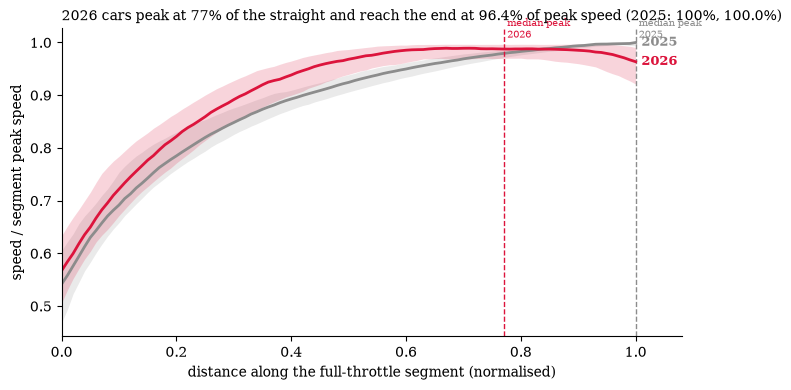

In [14]:
YEAR_COLOR = {2025: "0.55", 2026: "crimson"}


def fig_title(ax, text):
    ax.set_title(text, fontsize=10, loc="left")


prof = {y: np.vstack(v) for y, v in profiles.items()}
vmed = matched.groupby("Year").vmax_position.median()
fig, ax = plt.subplots(figsize=(8, 4))
end_frac = {}
for y, P in prof.items():
    q25, q50, q75 = np.nanpercentile(P, [25, 50, 75], axis=0)
    end_frac[y] = q50[-1]
    ax.fill_between(GRID, q25, q75, color=YEAR_COLOR[y], alpha=0.18, lw=0)
    ax.plot(GRID, q50, color=YEAR_COLOR[y], lw=2)
    ax.axvline(vmed[y], color=YEAR_COLOR[y], ls="--", lw=1)
    ax.text(1.01, q50[-1], f"{y}", color=YEAR_COLOR[y], va="center", fontsize=9, fontweight="bold")
    ax.text(vmed[y], 1.003, f" median peak\n {y}", color=YEAR_COLOR[y], fontsize=7, va="bottom")
ax.set(xlim=(0, 1.08), xlabel="distance along the full-throttle segment (normalised)", ylabel="speed / segment peak speed")
fig_title(ax, f"2026 cars peak at {vmed[2026]:.0%} of the straight and reach the end at {end_frac[2026]:.1%} of peak speed "
              f"(2025: {vmed[2025]:.0%}, {end_frac[2025]:.1%})")
fig.savefig(FIG / "fig_regs_speed_signature.pdf")
plt.show()

In [15]:
caption("Figure", "signature", f"Speed signature of the {len(per)} matched straights: each driver-straight resampled to normalised distance (0 = segment "
        f"start, 1 = end) and speed divided by its segment peak; line = median, band = IQR across driver-straights ({len(prof[2025])} in 2025, "
        f"{len(prof[2026])} in 2026); dashed = median peak position ({vmed[2025]:.2f} in 2025, {vmed[2026]:.2f} in 2026). Descriptive.")

*Figure 3. Speed signature of the 39 matched straights: each driver-straight resampled to normalised distance (0 = segment start, 1 = end) and speed divided by its segment peak; line = median, band = IQR across driver-straights (762 in 2025, 801 in 2026); dashed = median peak position (1.00 in 2025, 0.77 in 2026). Descriptive.*

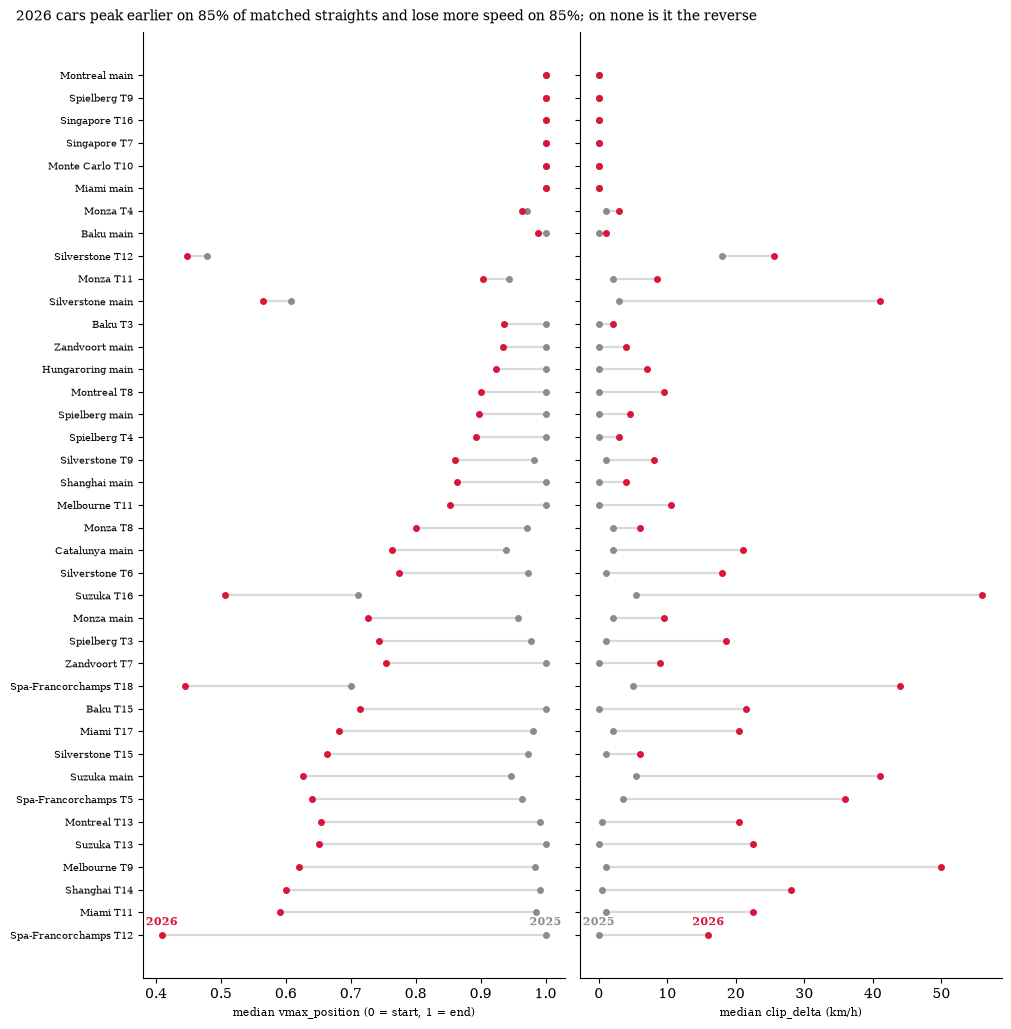

In [16]:
order = diff.sort_values("vmax_position", ascending=False).index
yy = np.arange(len(order))
fig, axes = plt.subplots(1, 2, figsize=(10, 0.22 * len(order) + 1.6), sharey=True, layout="constrained")
for ax, (m, label) in zip(axes, [("vmax_position", "median vmax_position (0 = start, 1 = end)"), ("clip_delta", "median clip_delta (km/h)")]):
    a, b = per.loc[order, (m, 2025)], per.loc[order, (m, 2026)]
    ax.hlines(yy, a, b, color="0.85", lw=1.6, zorder=1)
    ax.scatter(a, yy, color=YEAR_COLOR[2025], s=16, zorder=2)
    ax.scatter(b, yy, color=YEAR_COLOR[2026], s=16, zorder=3)
    ax.set_xlabel(label, fontsize=8)
    for y, x in [(2025, a.iloc[-1]), (2026, b.iloc[-1])]:
        ax.annotate(str(y), (x, yy[-1]), xytext=(0, 7), textcoords="offset points", ha="center", color=YEAR_COLOR[y], fontsize=8, fontweight="bold")
axes[0].set_yticks(yy, order, fontsize=7)
axes[0].invert_yaxis()
_earlier, _more = (diff.vmax_position < 0).mean(), (diff.clip_delta > 0).mean()
_rev = int(((diff.vmax_position > 0) | (diff.clip_delta < 0)).sum())
fig.suptitle(f"2026 cars peak earlier on {_earlier:.0%} of matched straights and lose more speed on {_more:.0%}; "
             + ("on none is it the reverse" if _rev == 0 else f"{_rev} straights show the reverse"), fontsize=10, x=0.01, ha="left")
fig.savefig(FIG / "fig_regs_dumbbell.pdf")
plt.show()

In [17]:
caption("Figure", "dumbbell", f"Each matched straight shown individually, 2025 (grey) and 2026 (accent) medians joined by a line, sorted by the change in "
        "vmax_position; showing paired data individually rather than as bars follows Weissgerber et al. (2015, PLOS Biology 13(4): e1002128, "
        f"Fig 2). Median change: vmax_position {diff.vmax_position.median():+.2f}, clip_delta {diff.clip_delta.median():+.1f} km/h. Descriptive.")

*Figure 4. Each matched straight shown individually, 2025 (grey) and 2026 (accent) medians joined by a line, sorted by the change in vmax_position; showing paired data individually rather than as bars follows Weissgerber et al. (2015, PLOS Biology 13(4): e1002128, Fig 2). Median change: vmax_position -0.15, clip_delta +7.5 km/h. Descriptive.*

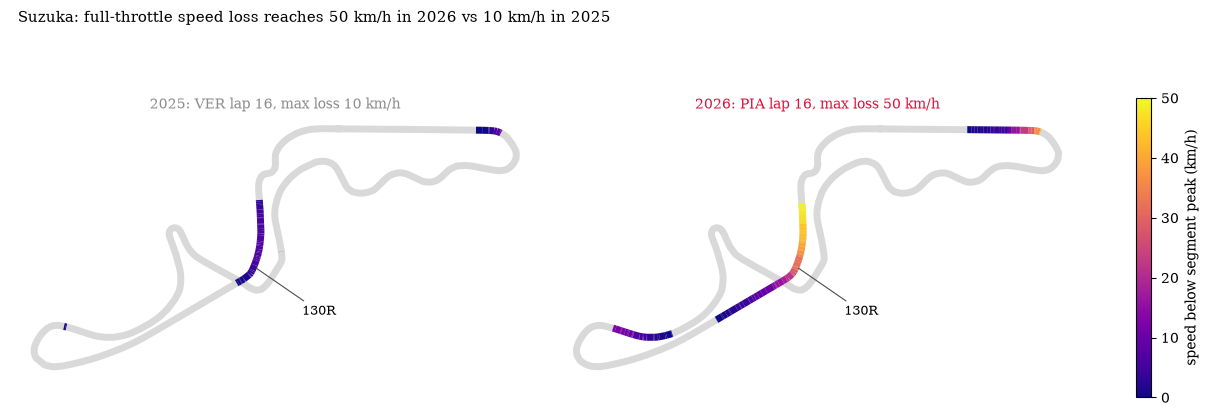

In [18]:
def rotate(xy, angle):
    """Rotate [n, 2] or [2] coordinates by `angle` radians (FastF1 track-map example)."""
    return np.matmul(xy, np.array([[np.cos(angle), np.sin(angle)], [-np.sin(angle), np.cos(angle)]]))


def clipping_lap(year, rnd, key):
    """Fastest freeze-free push lap and, per telemetry sample, speed below the segment peak from the peak to the segment end."""
    ses = sessions.get((year, rnd)) or load_quali(year, rnd)
    load_openf1_brake(key, ses.drivers)  # same brake-unknown handling as run_session
    push, _ = push_laps(ses)
    lap = next(l for _, l in push.sort_values("LapTime").iterlaps() if not freeze_mask(l.get_car_data())[0].any())
    car = lap.get_car_data().add_distance()
    loss = pd.Series(np.nan, index=car.index)
    for a, b in full_throttle_segments(car, lap["Time"]):
        sp = car.Speed.to_numpy()[a:b]
        k = a + len(sp) - 1 - int(np.argmax(sp[::-1]))  # peak = last sample at maximum speed, as in segment_metrics
        loss.iloc[k:b] = sp.max() - car.Speed.to_numpy()[k:b]
    tel = pd.merge_asof(lap.telemetry[["SessionTime", "X", "Y"]].sort_values("SessionTime"),  # merged telemetry for drawing only (HAC)
                        pd.DataFrame({"SessionTime": car.SessionTime, "Loss": loss.to_numpy()}), on="SessionTime", direction="nearest")
    return ses, lap, tel


suz = pairs[pairs.CircuitName == "Suzuka"].iloc[0]
maps = {y: clipping_lap(y, rnd, key) for y, rnd, key in [(2025, suz.Round25, suz.Key25), (2026, suz.Round26, suz.Key26)]}
norm = plt.Normalize(0, max(np.nanmax(t.Loss) for _, _, t in maps.values()))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
for ax, (y, (ses, lap, tel)) in zip(axes, maps.items()):
    ci = ses.get_circuit_info()
    ang = ci.rotation / 180 * np.pi
    pts = rotate(tel[["X", "Y"]].to_numpy(), ang).reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)  # FastF1 example "Speed visualization on track map"
    on = tel.Loss.notna().to_numpy()
    keep = on[:-1] & on[1:]
    ax.plot(pts[:, 0, 0], pts[:, 0, 1], color="0.85", lw=5, zorder=1, solid_capstyle="round")
    lc = LineCollection(segs[keep], cmap="plasma", norm=norm, lw=5, zorder=2)
    lc.set_array(tel.Loss.to_numpy()[:-1][keep])
    ax.add_collection(lc)
    c15 = ci.corners.set_index("Number").loc[15]
    p15 = rotate([c15.X, c15.Y], ang)
    ax.annotate("130R", xy=p15, xytext=p15 + np.array([2000, -2000]), fontsize=9, arrowprops=dict(arrowstyle="-", color="0.3", lw=0.8))
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{y}: {lap['Driver']} lap {int(lap['LapNumber'])}, max loss {np.nanmax(tel.Loss):.0f} km/h", fontsize=10, color=YEAR_COLOR[y])
fig.colorbar(lc, ax=axes, shrink=0.7, label="speed below segment peak (km/h)")
fig.suptitle(f"Suzuka: full-throttle speed loss reaches {np.nanmax(maps[2026][2].Loss):.0f} km/h in 2026 vs {np.nanmax(maps[2025][2].Loss):.0f} km/h in 2025",
             fontsize=11, x=0.01, ha="left")
fig.savefig(FIG / "fig_regs_suzuka_maps.pdf")
plt.show()

In [19]:
caption("Figure", "maps", "Suzuka clipping maps on one colour scale, fastest freeze-free push lap per year (" + "; ".join(
    f"{y} {l['Driver']} lap {int(l['LapNumber'])}, maximum {np.nanmax(t.Loss):.0f} km/h" for y, (_, l, t) in maps.items())
    + "): colour = speed below the segment's peak from the peak to the segment end; grey = outside full-throttle segments or before the peak. Descriptive.")

*Figure 5. Suzuka clipping maps on one colour scale, fastest freeze-free push lap per year (2025 VER lap 16, maximum 10 km/h; 2026 PIA lap 16, maximum 50 km/h): colour = speed below the segment's peak from the peak to the segment end; grey = outside full-throttle segments or before the peak. Descriptive.*

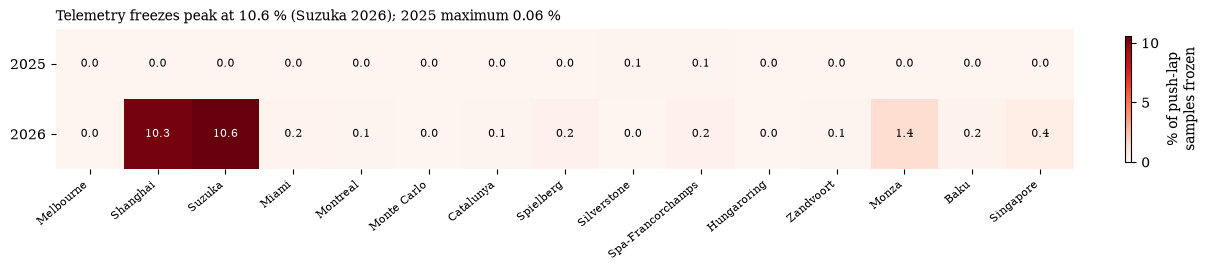

In [20]:
q26 = pd.read_csv(OUT26 / "qc_summary.csv").set_index("Round")
cal = pd.DataFrame({2025: [qc25.set_index("Circuit").loc[p.CircuitName, "push_lap_frozen_pct_mean"] for p in pairs.itertuples()],
                    2026: [q26.loc[p.Round26, "push_lap_frozen_pct_mean"] for p in pairs.itertuples()]}, index=pairs.CircuitName).T
fig, ax = plt.subplots(figsize=(12, 2.6), layout="constrained")
im = ax.imshow(cal.to_numpy(), cmap="Reds", aspect="auto", vmin=0)
for (i, j), v in np.ndenumerate(cal.to_numpy()):
    ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color="white" if v > cal.to_numpy().max() / 2 else "black")
ax.set_xticks(range(cal.shape[1]), cal.columns, rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(2), cal.index)
ax.spines[["left", "bottom"]].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.9, label="% of push-lap\nsamples frozen")
_mx = cal.loc[2026].idxmax()
fig_title(ax, f"Telemetry freezes peak at {cal.loc[2026].max():.1f} % ({_mx} 2026); 2025 maximum {cal.loc[2025].max():.2f} %")
fig.savefig(FIG / "fig_regs_freeze_calendar.pdf")
plt.show()

In [21]:
caption("Figure", "calendar", f"Freeze share per paired circuit (2026 calendar order) and year: 2025 range {cal.loc[2025].min():.2f}–{cal.loc[2025].max():.2f} %, "
        f"2026 range {cal.loc[2026].min():.2f}–{cal.loc[2026].max():.2f} %; circuits above 1 % in 2026: "
        f"{', '.join(cal.columns[cal.loc[2026] > 1]) or 'none'}.")

*Figure 6. Freeze share per paired circuit (2026 calendar order) and year: 2025 range 0.00–0.06 %, 2026 range 0.00–10.60 %; circuits above 1 % in 2026: Shanghai, Suzuka, Monza.*